In [7]:
# We start by importing all the necessary packages
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import torch
from tqdm import tqdm
import math
from Python_files import time_integration_functions as TST
from Python_files import TLM_Test as TT
from Python_files import ETLM as ETLMC
from Python_files import LETLM_ensemble as LETLMC
from Python_files import IETLM_ensemble as IETLMC
from Python_files import GETLM as GETLMC
from Python_files import GETLM_experiment_neat as GEN
#  We also need to set the precision to be higher as we are working with very small perturbations
torch.set_default_dtype(torch.float64)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
# we now define stuff as required
model = TST.rk4_L96

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.05 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)

perturbation_size = 10**(-7)
ensemble_size = 30
num_steps = 40
trials = 1
LETLM_stencil = [[0], [-9,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8]]
IETLM_stencil = [[-5,-4,-4,-2,-1,0,1,2,3,4], [-5,-4,-4,-2,-1,0,1,2,3,4]]
GETLM_stencil = [[-2,-1,0,1], [-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7],[-2,-1,0,1]]

x_values = np.arange(1, num_steps+1)  


  0%|          | 0/1 [00:00<?, ?it/s]

perturbation_size 1e-07 | dt 0.05 | F 8 | |Test_pert| 7.419615727583015e-07
A 1 pert: 7.850545871989402e-07 | unpert_run mismatch: 0.0 | shapes: (1,) (1,)
A 2 pert: 9.44327631477099e-07 | unpert_run mismatch: 0.0 | shapes: (1,) (1,)
A 3 pert: 1.201729515256582e-06 | unpert_run mismatch: 0.0 | shapes: (1,) (1,)
A 4 pert: 1.5873908174689618e-06 | unpert_run mismatch: 0.0 | shapes: (1,) (1,)
A 5 pert: 2.1577905589396375e-06 | unpert_run mismatch: 0.0 | shapes: (1,) (1,)
B 1 7.419615732275118e-07
B 2 7.850545871989402e-07
B 3 9.44327631477099e-07
B 4 1.201729515256582e-06
B 5 1.5873908174689618e-06
B 6 2.1577905589396375e-06


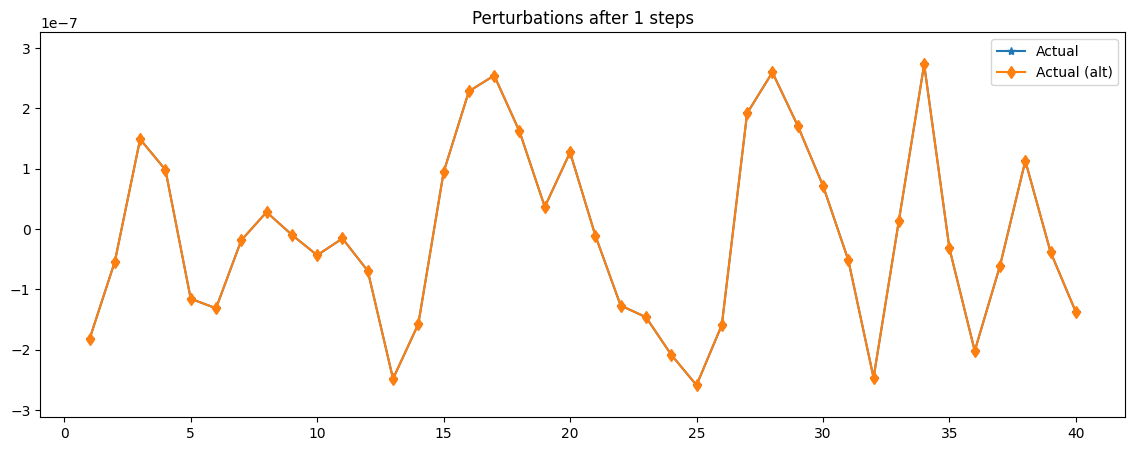

<Figure size 640x480 with 0 Axes>

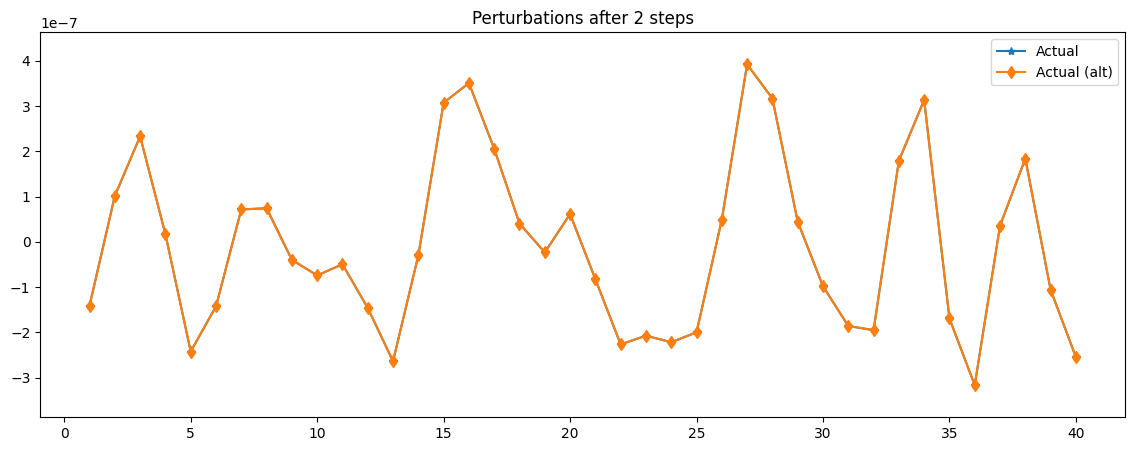

<Figure size 640x480 with 0 Axes>

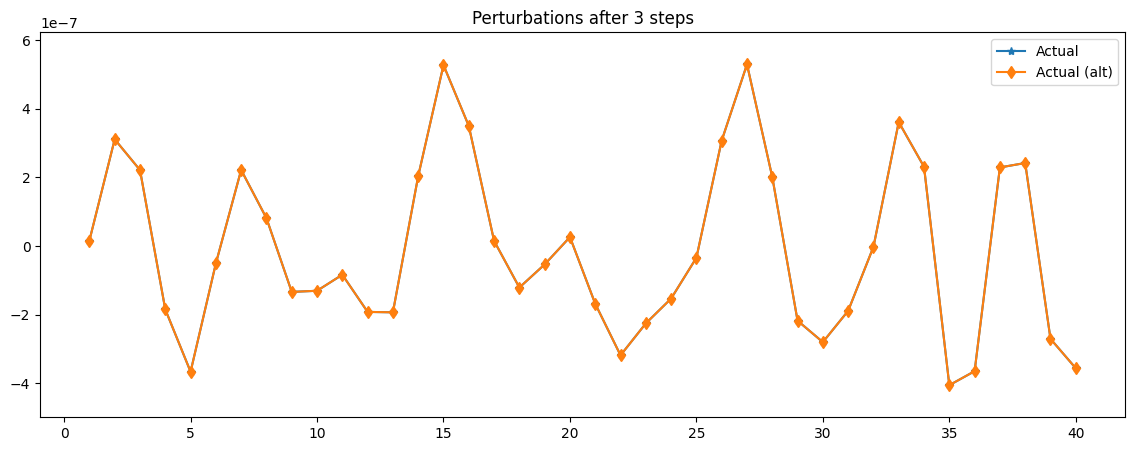

<Figure size 640x480 with 0 Axes>

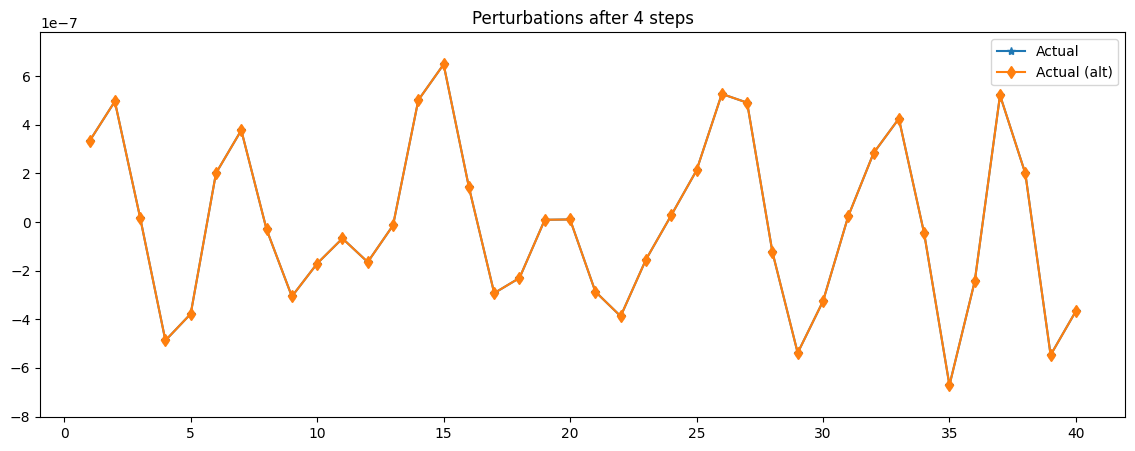

<Figure size 640x480 with 0 Axes>

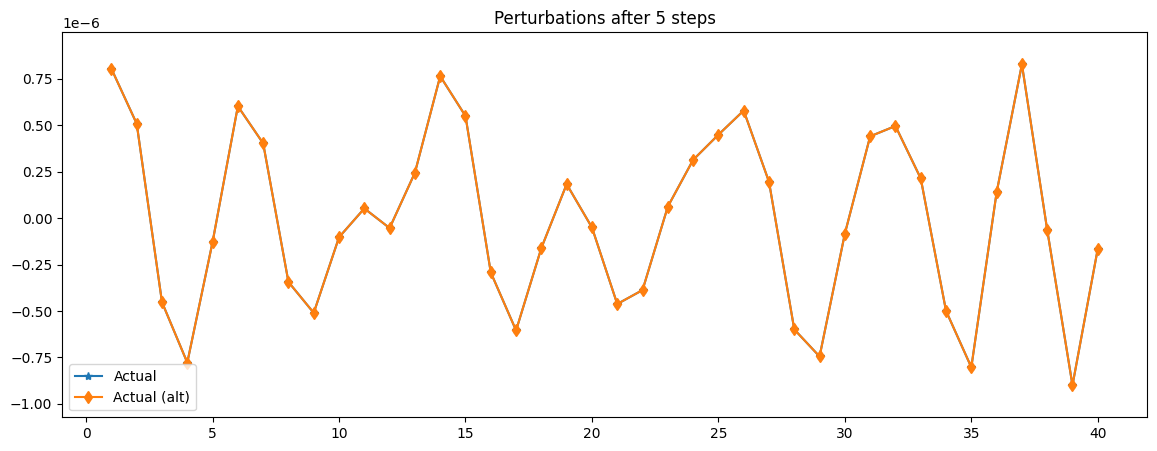

<Figure size 640x480 with 0 Axes>

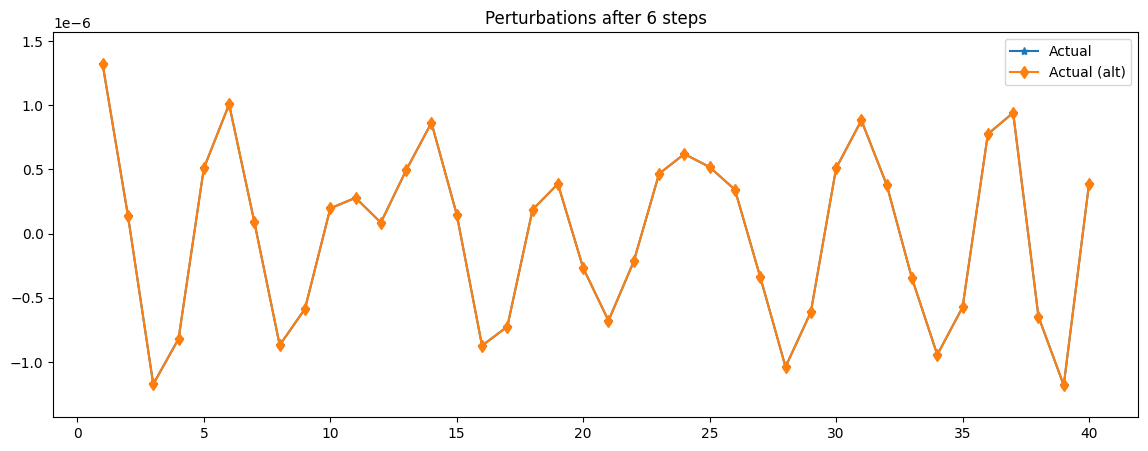

<Figure size 640x480 with 0 Axes>

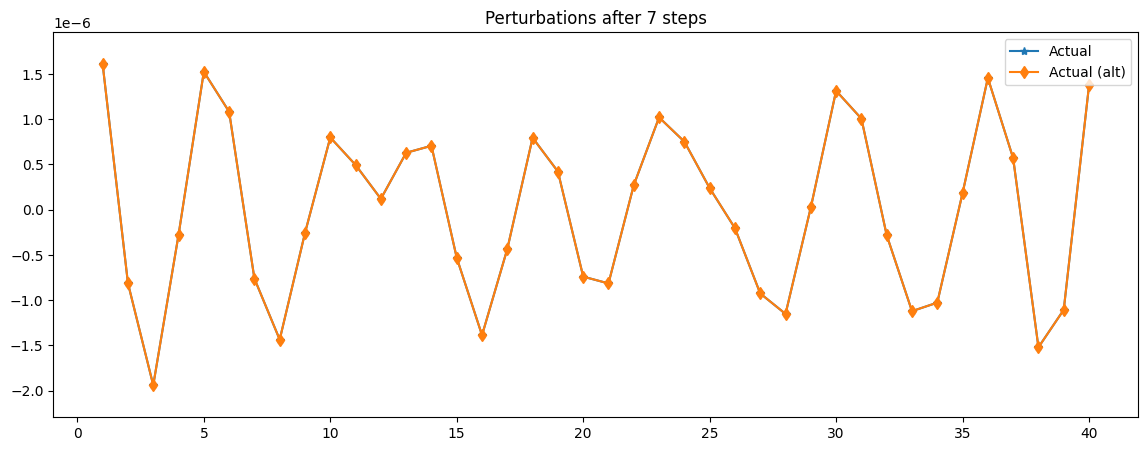

<Figure size 640x480 with 0 Axes>

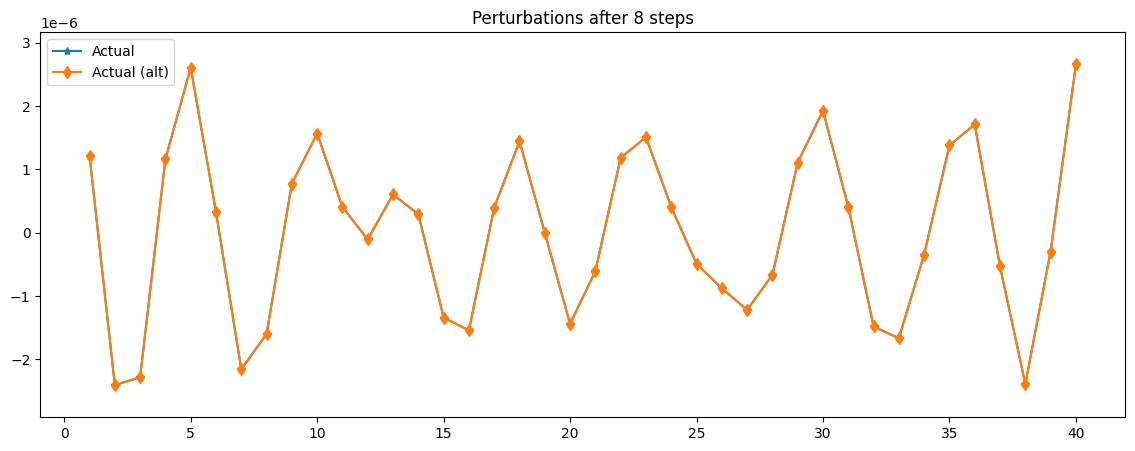

<Figure size 640x480 with 0 Axes>

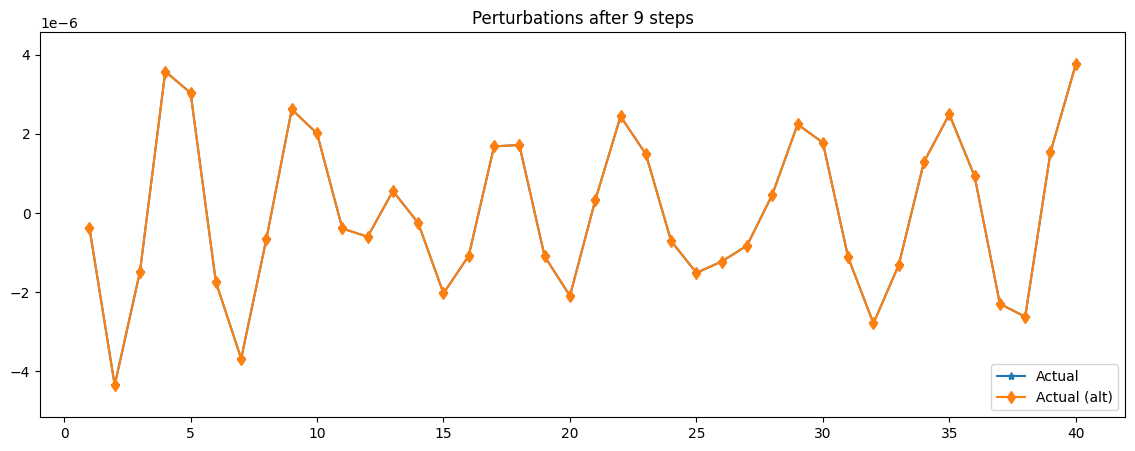

<Figure size 640x480 with 0 Axes>

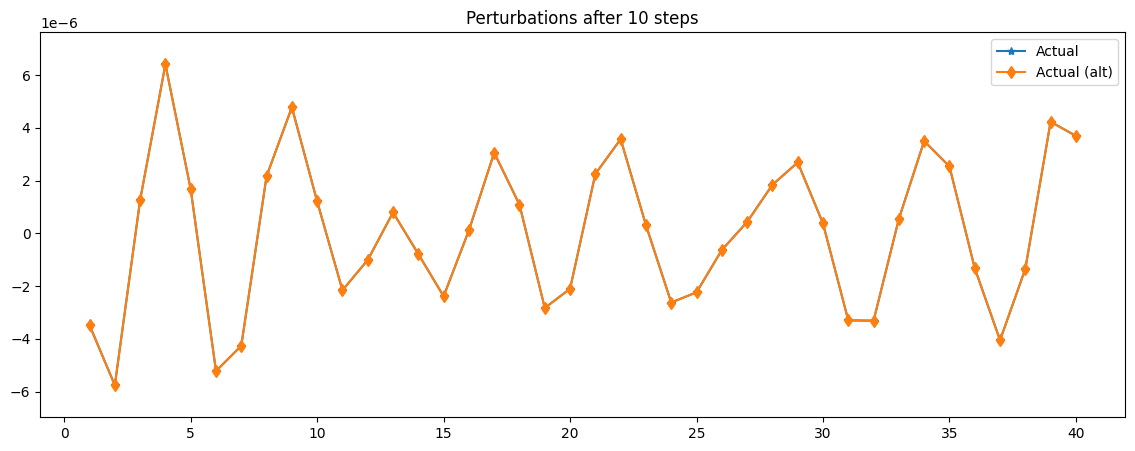

<Figure size 640x480 with 0 Axes>

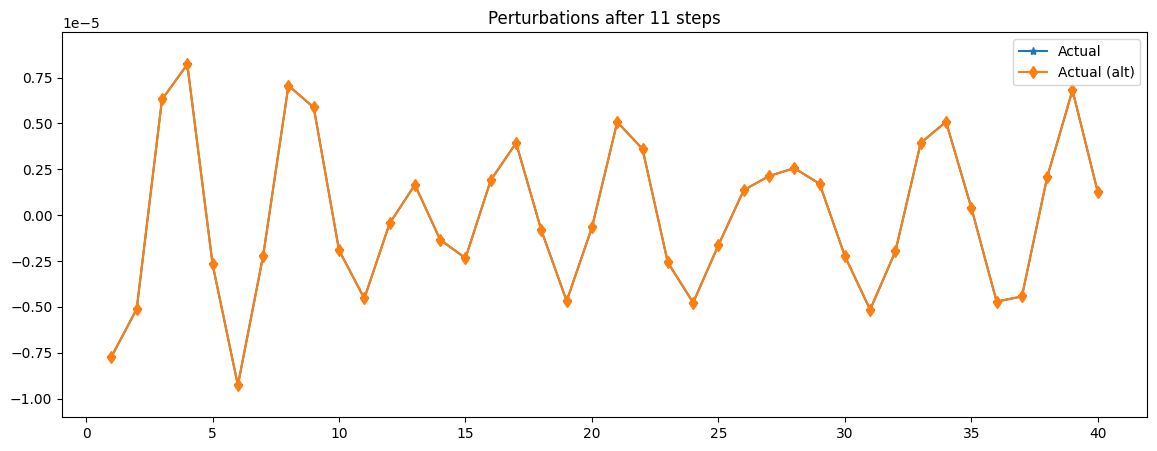

<Figure size 640x480 with 0 Axes>

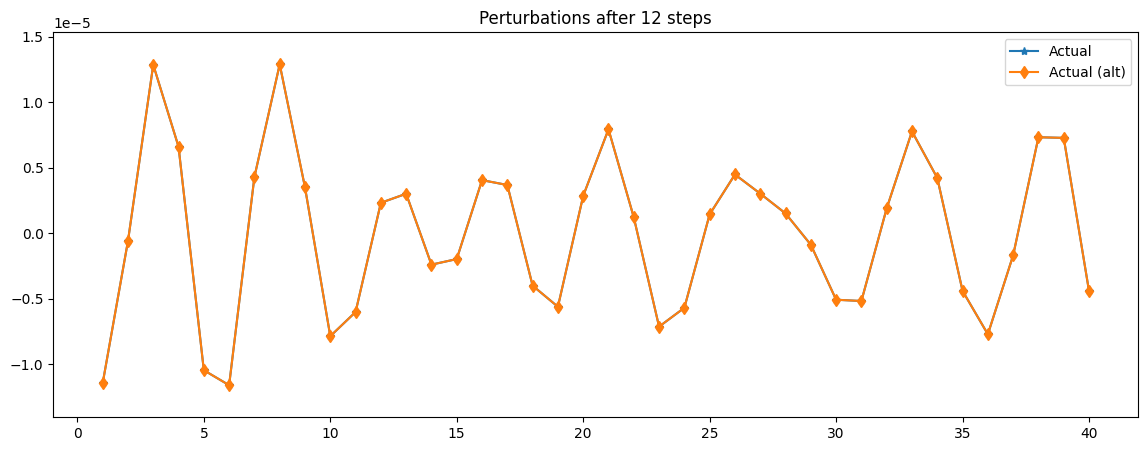

<Figure size 640x480 with 0 Axes>

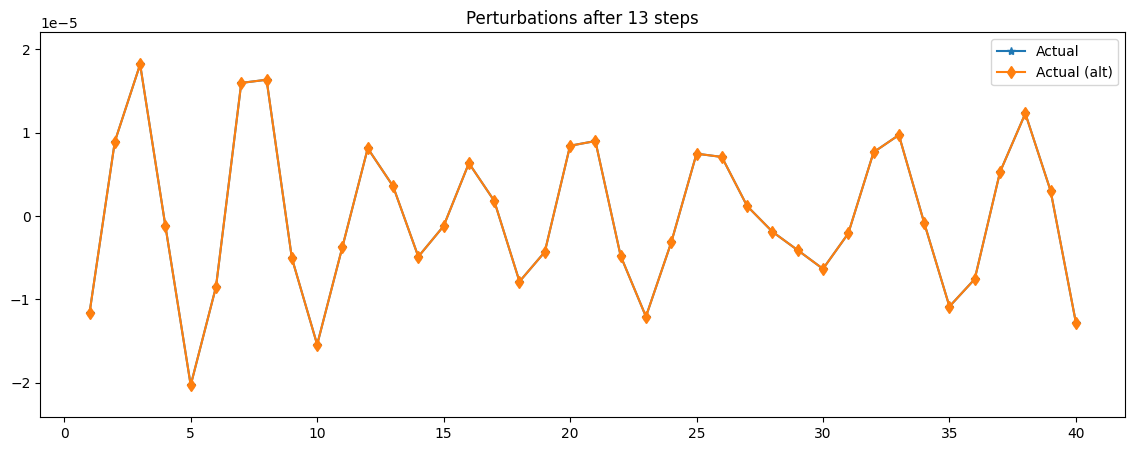

<Figure size 640x480 with 0 Axes>

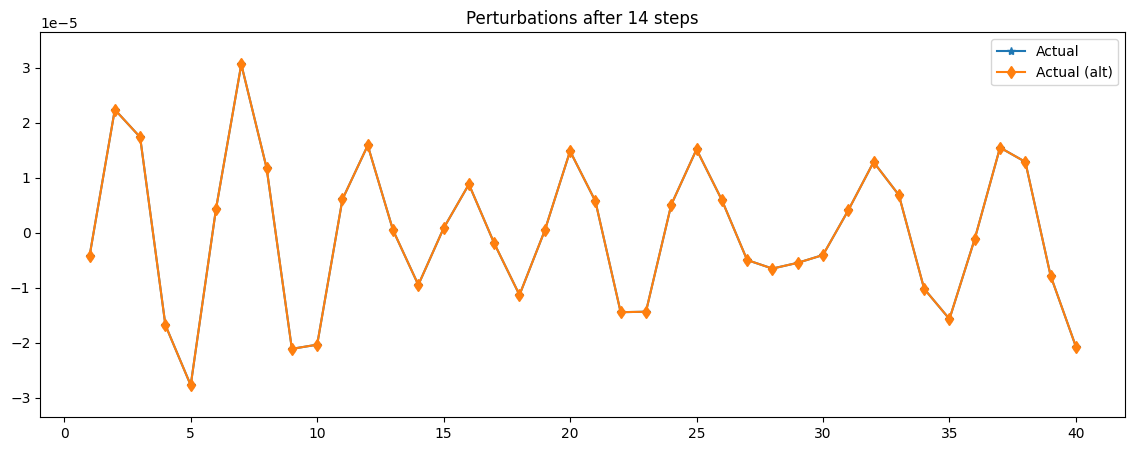

<Figure size 640x480 with 0 Axes>

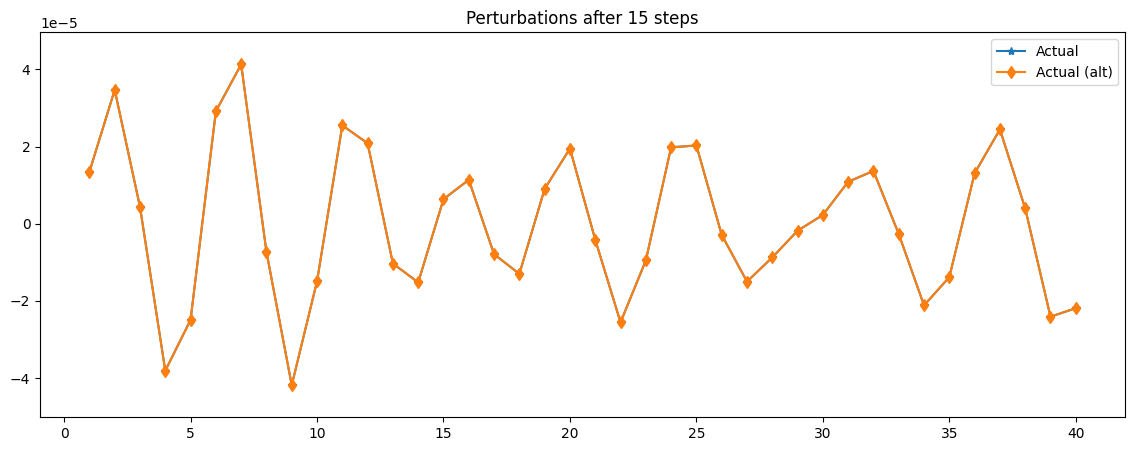

<Figure size 640x480 with 0 Axes>

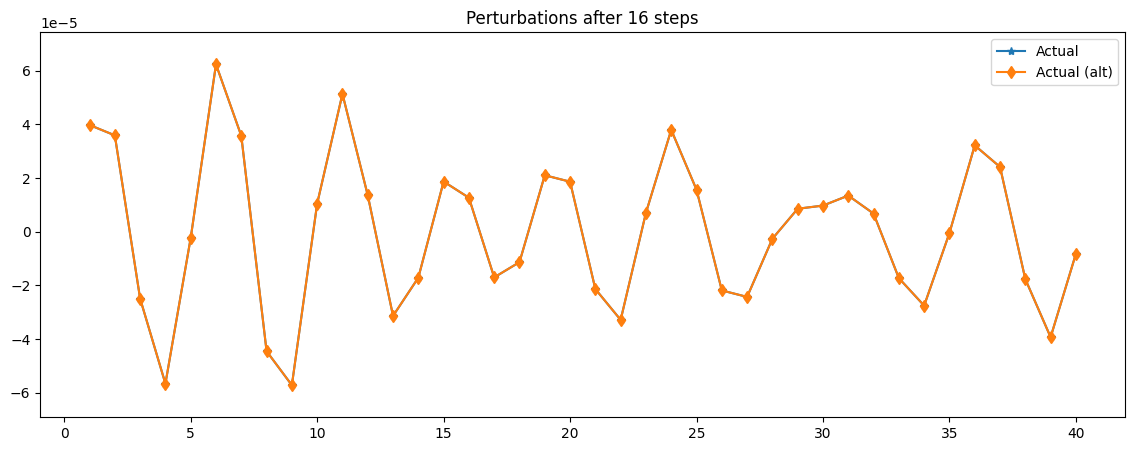

<Figure size 640x480 with 0 Axes>

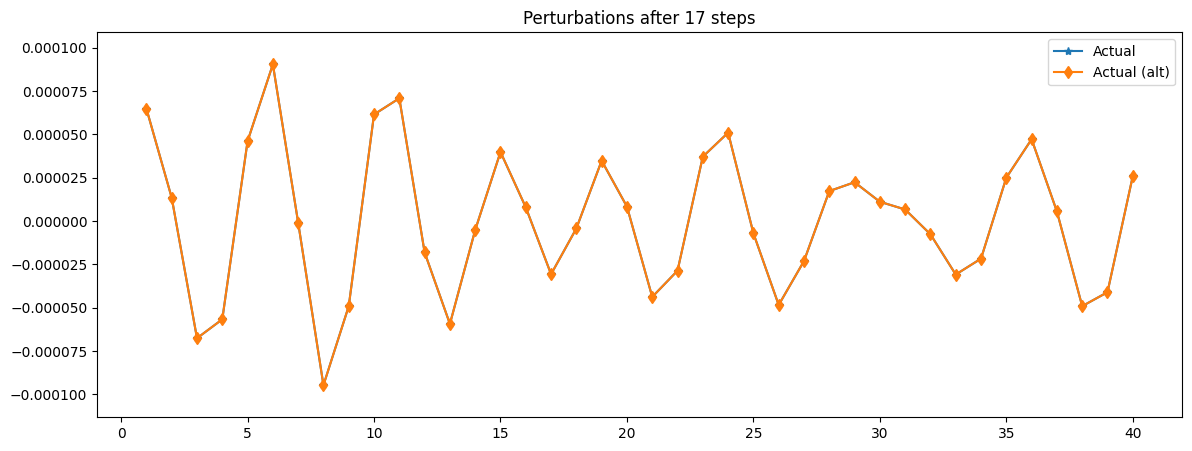

<Figure size 640x480 with 0 Axes>

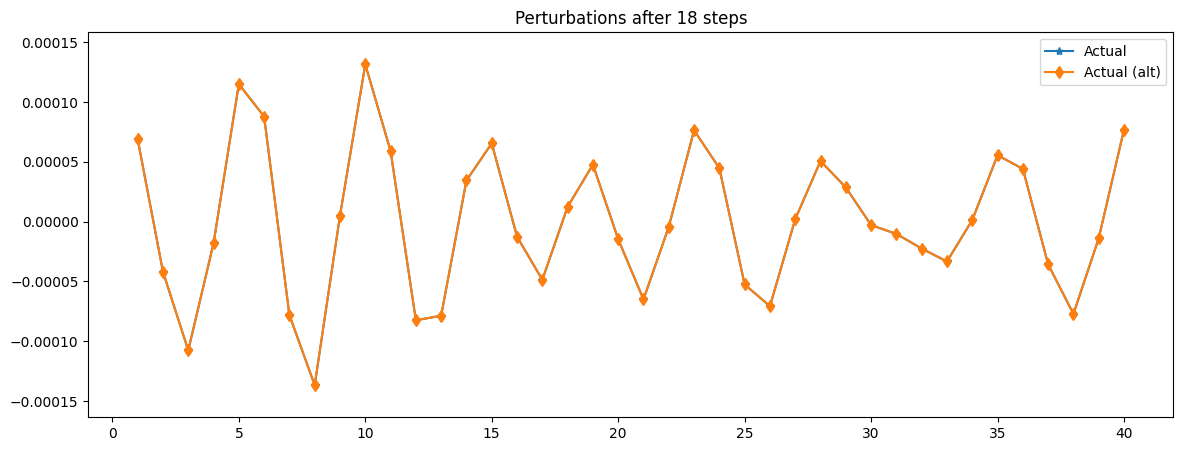

<Figure size 640x480 with 0 Axes>

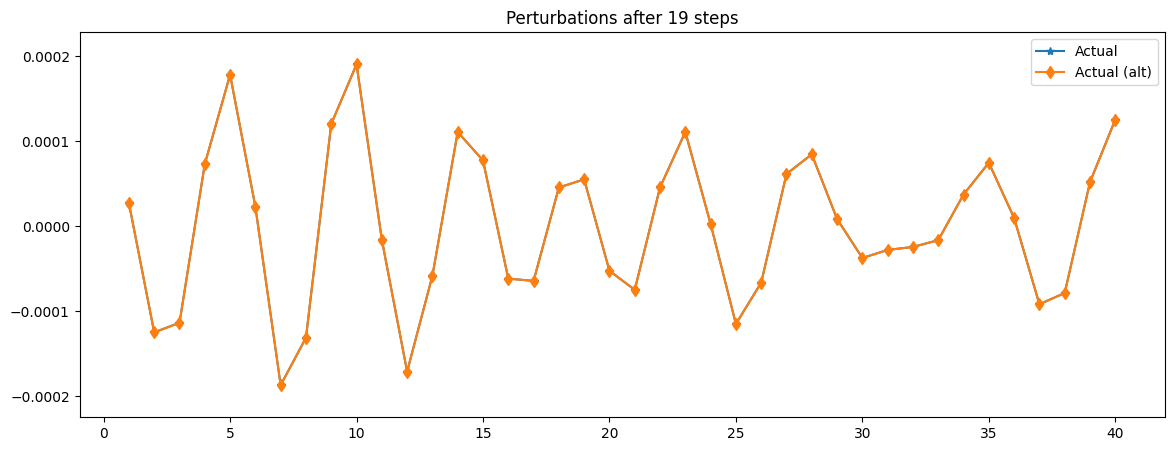

<Figure size 640x480 with 0 Axes>

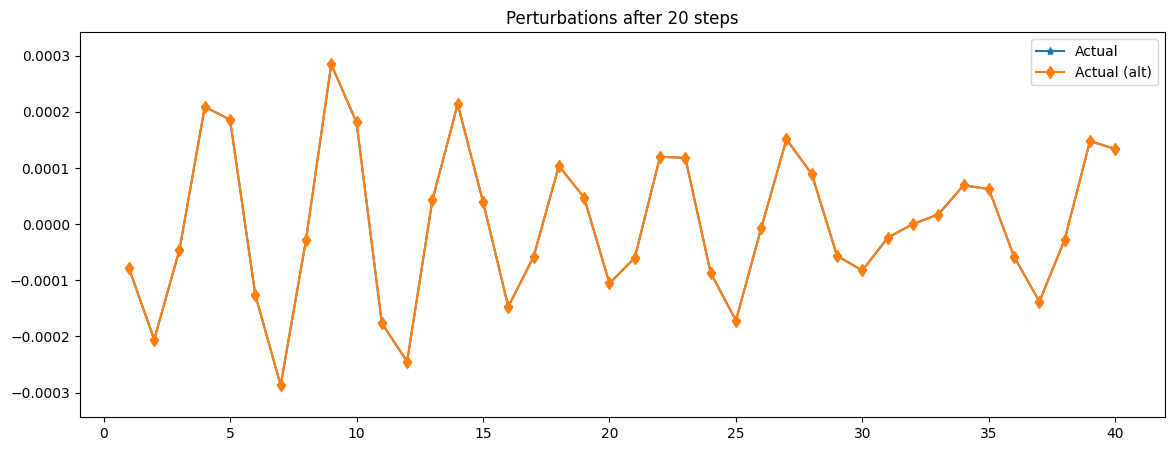

<Figure size 640x480 with 0 Axes>

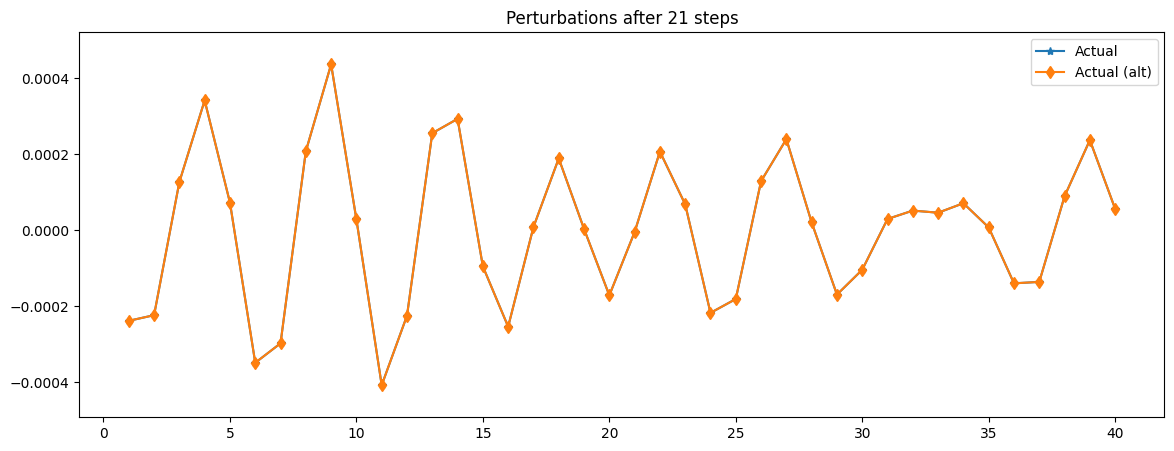

<Figure size 640x480 with 0 Axes>

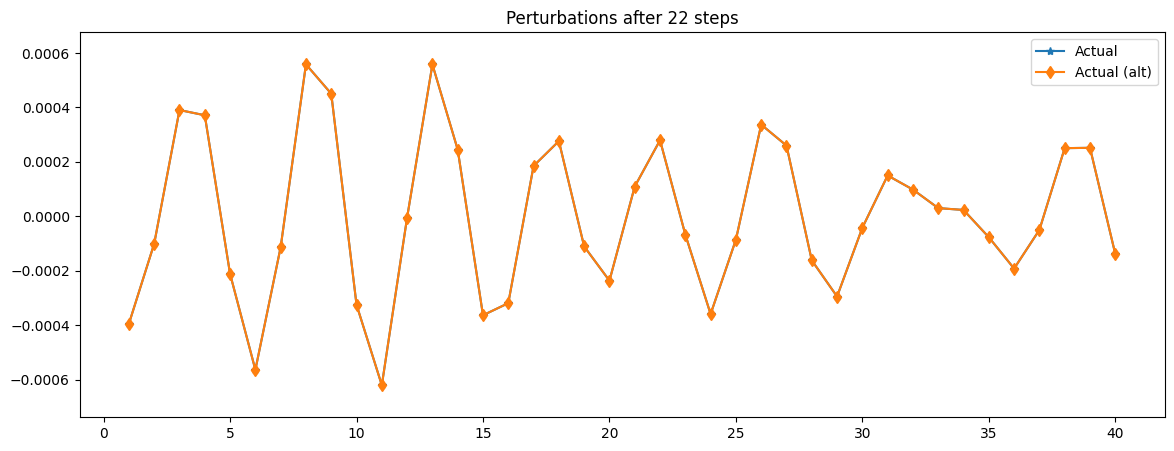

<Figure size 640x480 with 0 Axes>

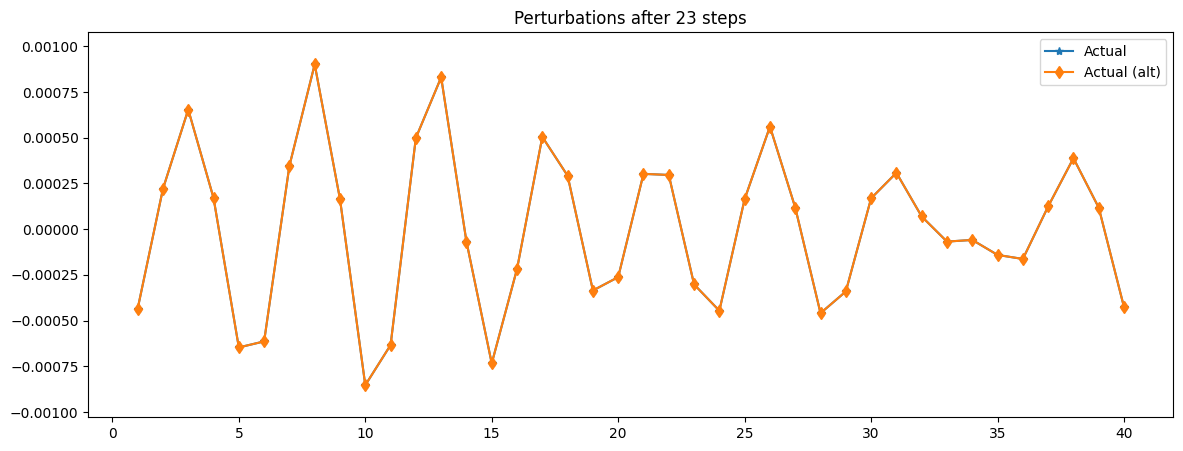

<Figure size 640x480 with 0 Axes>

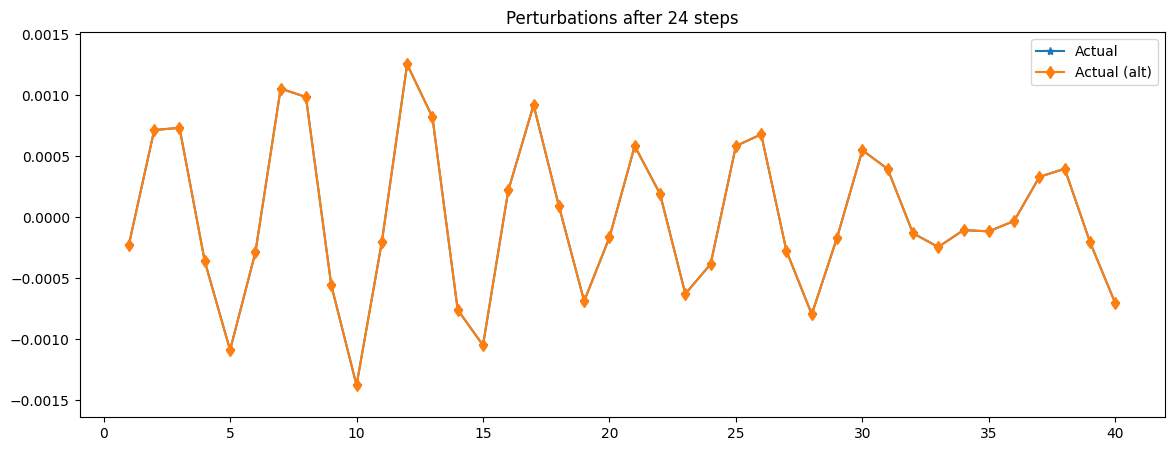

<Figure size 640x480 with 0 Axes>

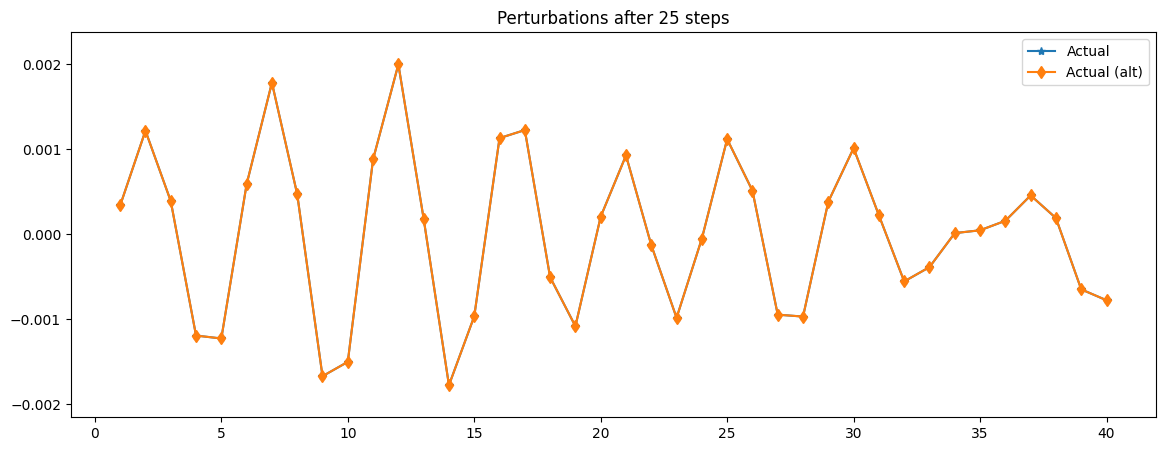

<Figure size 640x480 with 0 Axes>

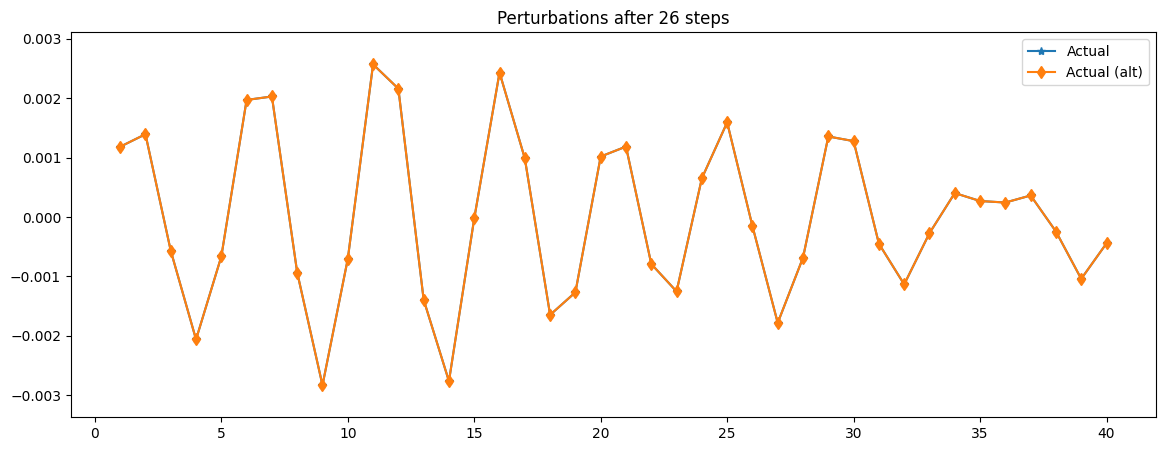

<Figure size 640x480 with 0 Axes>

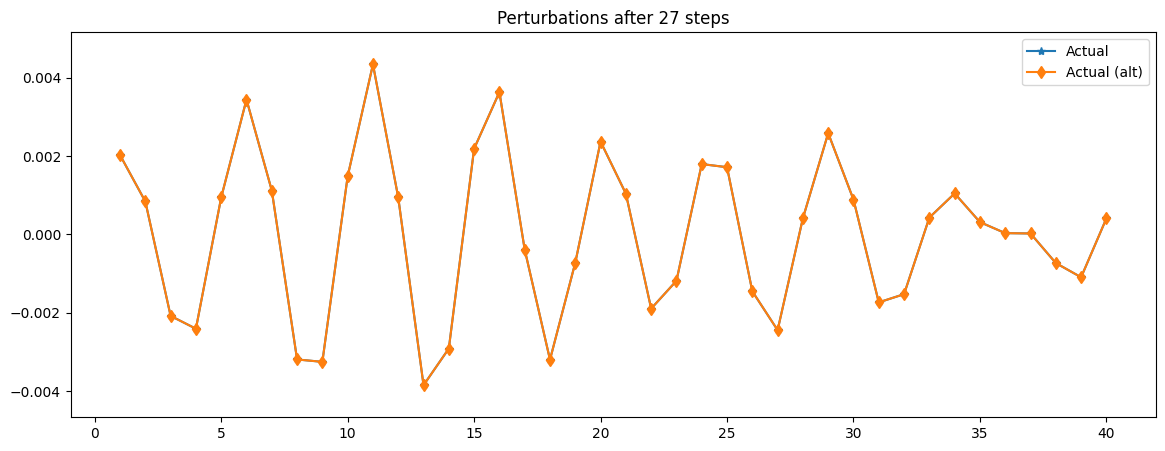

<Figure size 640x480 with 0 Axes>

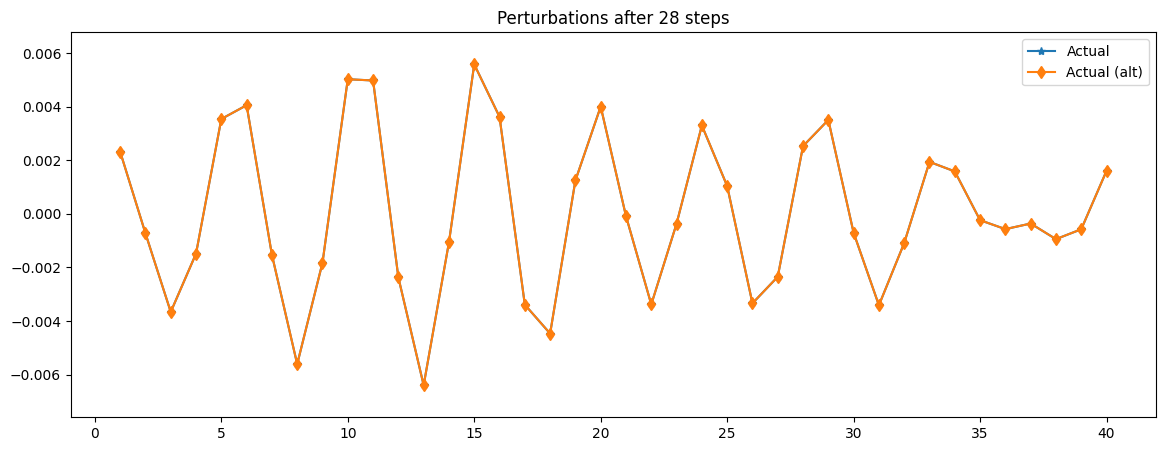

<Figure size 640x480 with 0 Axes>

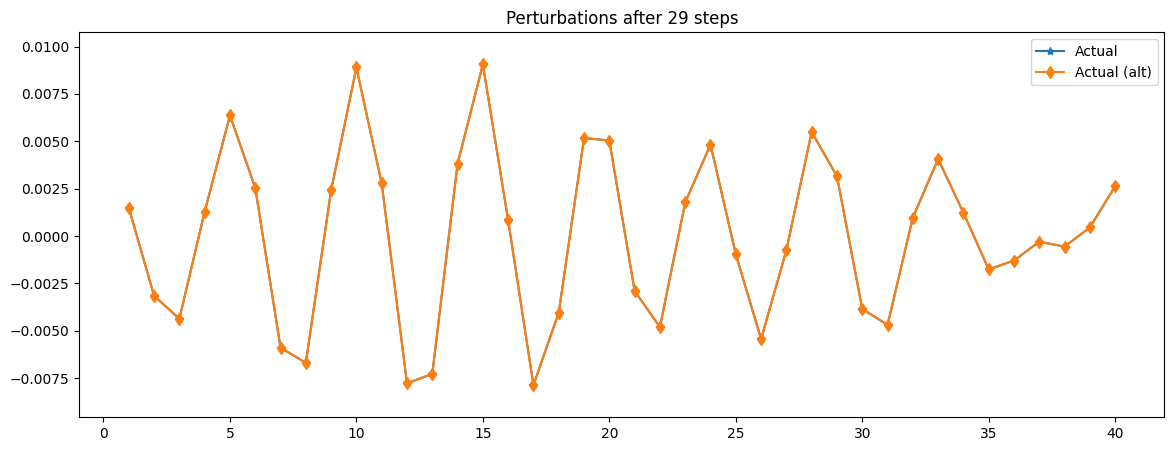

<Figure size 640x480 with 0 Axes>

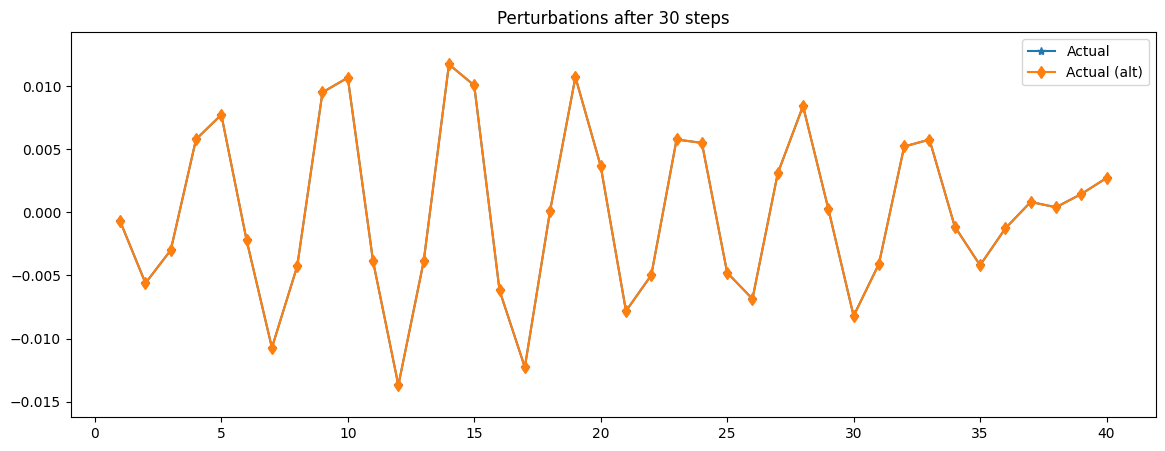

<Figure size 640x480 with 0 Axes>

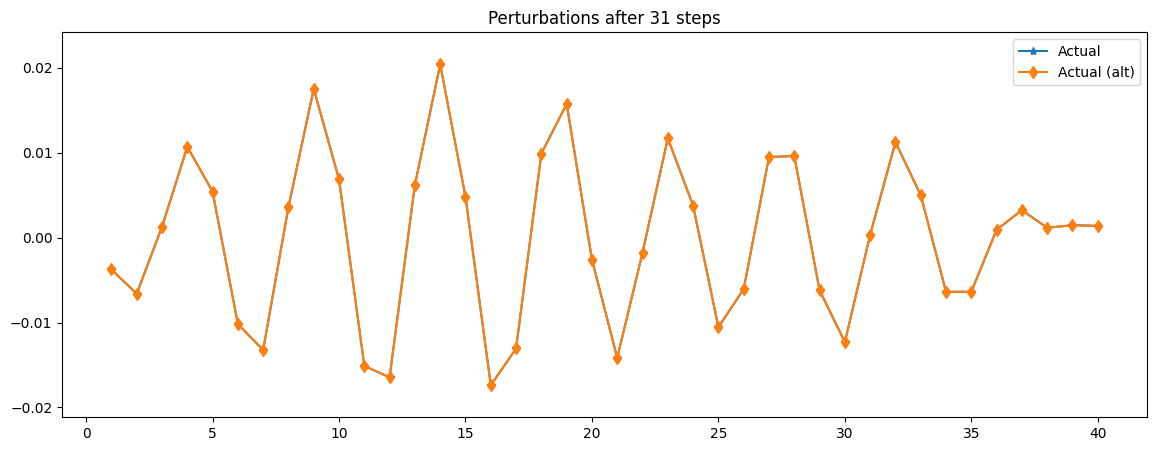

<Figure size 640x480 with 0 Axes>

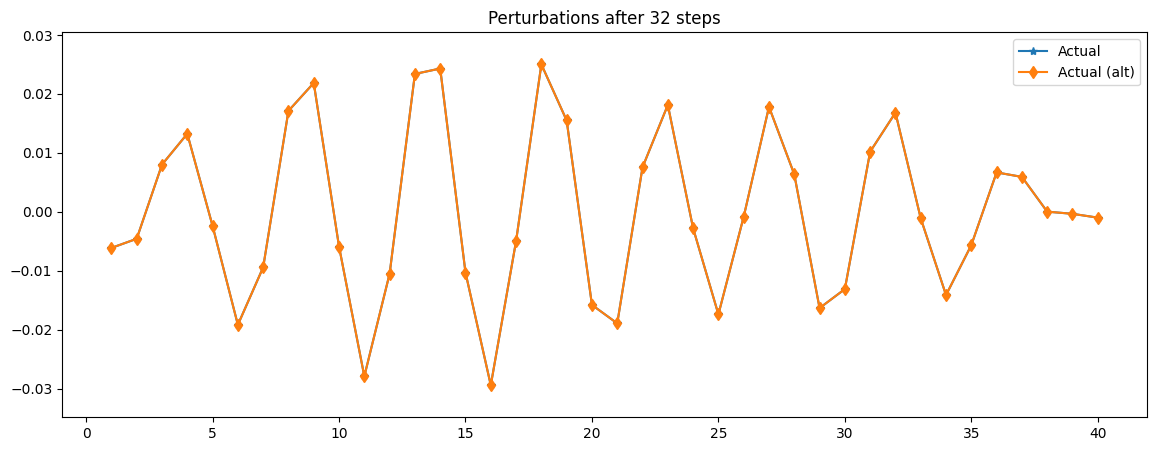

<Figure size 640x480 with 0 Axes>

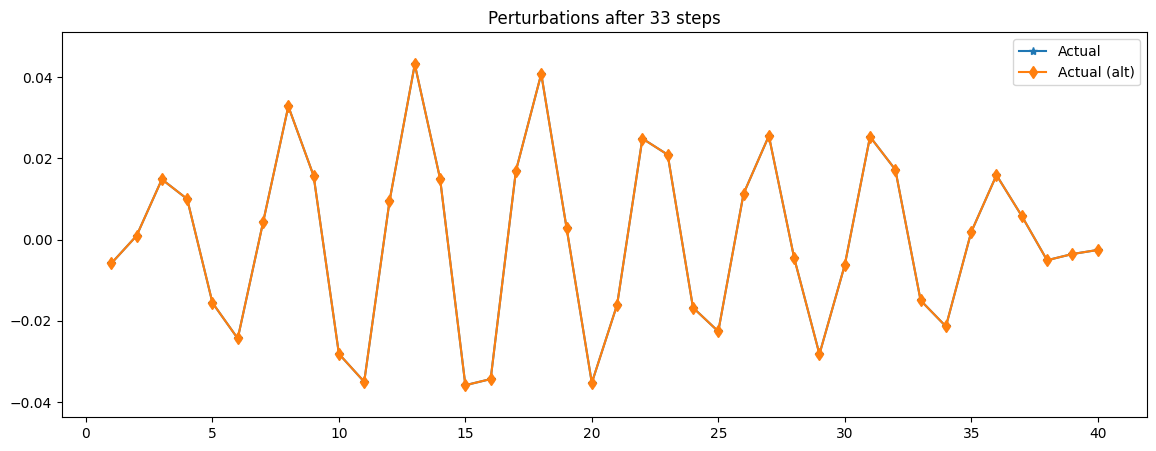

<Figure size 640x480 with 0 Axes>

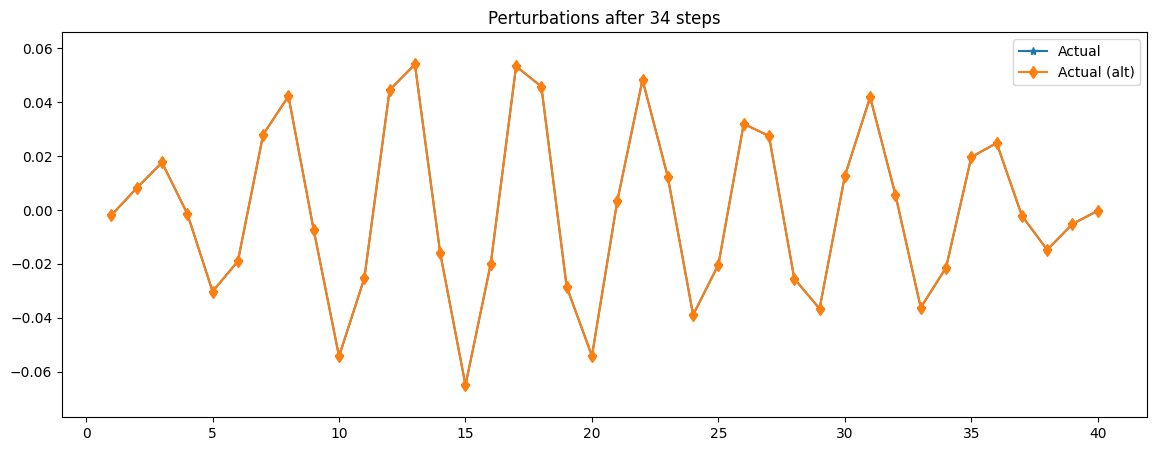

<Figure size 640x480 with 0 Axes>

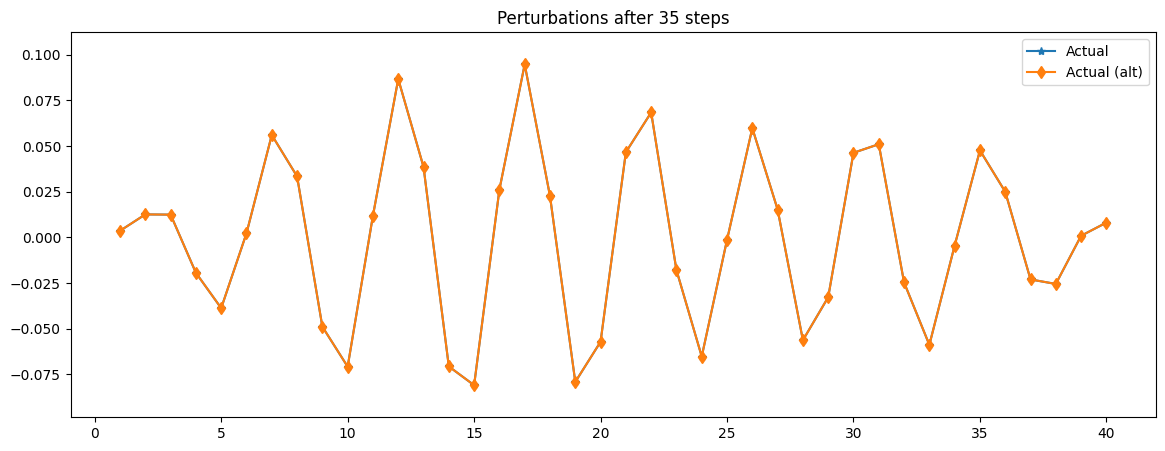

<Figure size 640x480 with 0 Axes>

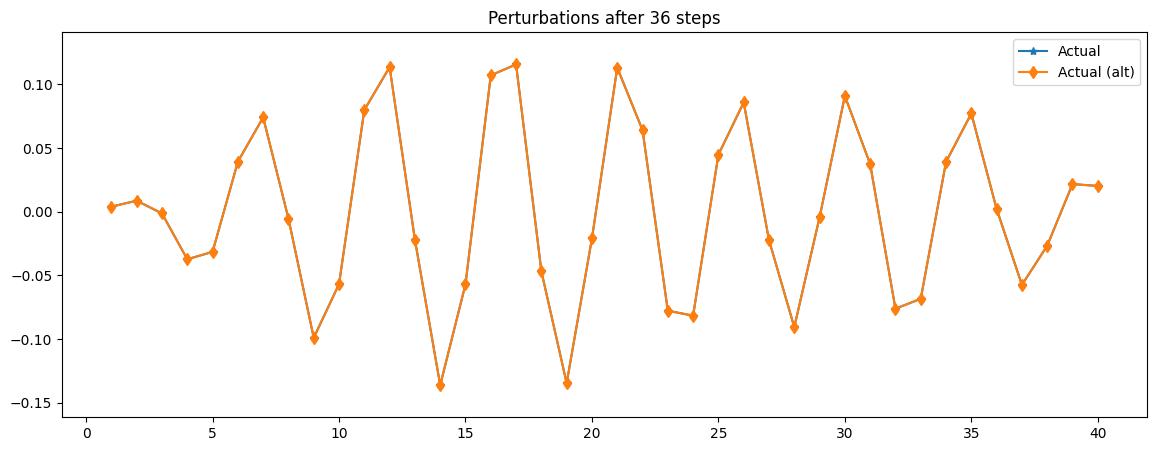

<Figure size 640x480 with 0 Axes>

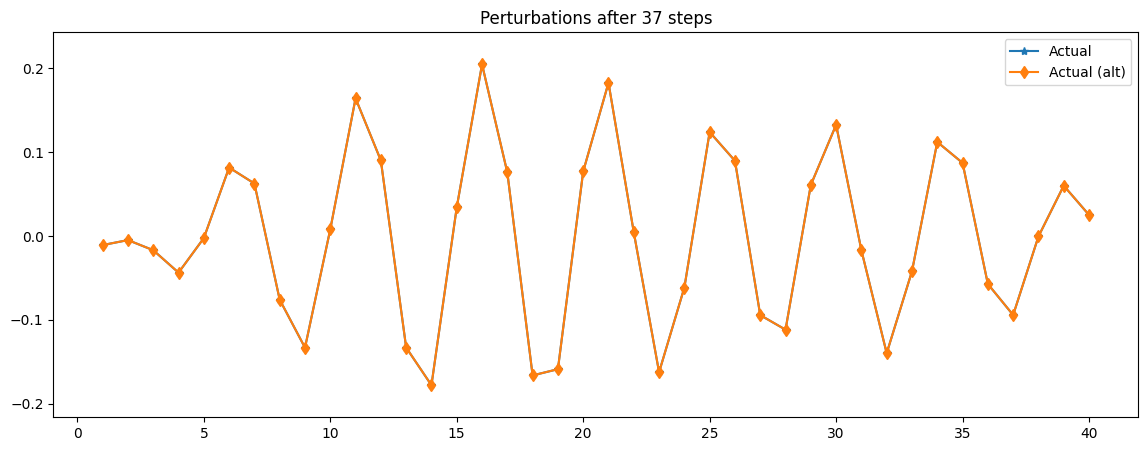

<Figure size 640x480 with 0 Axes>

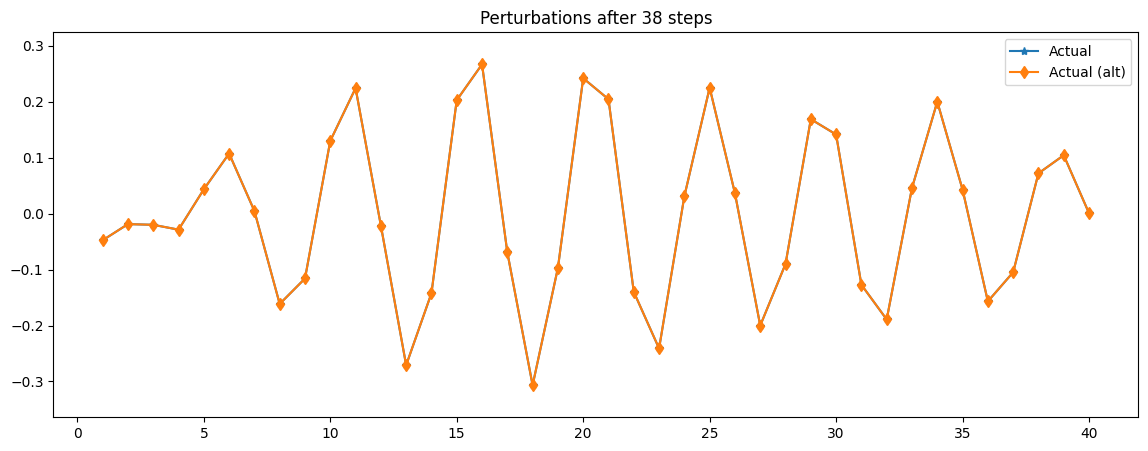

<Figure size 640x480 with 0 Axes>

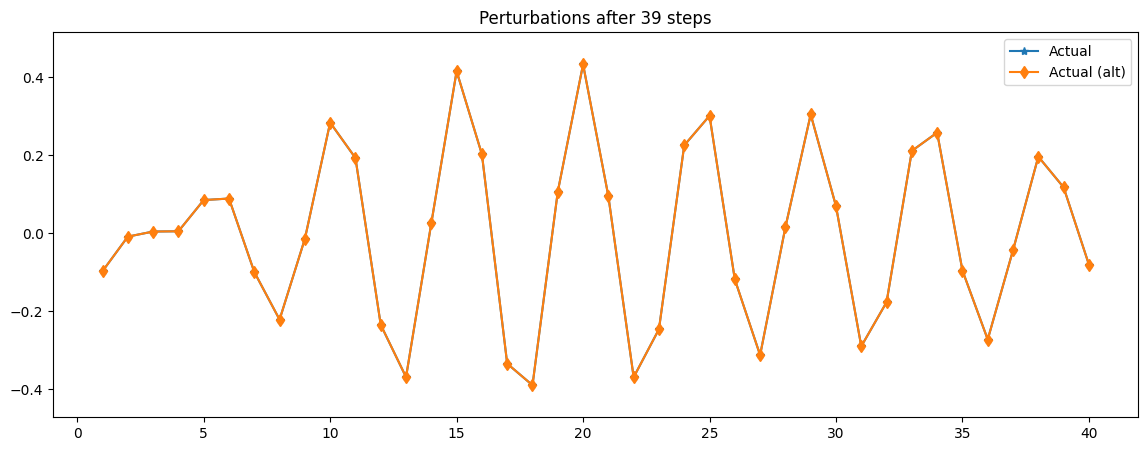

100%|██████████| 1/1 [00:03<00:00,  3.23s/it]

torch.Size([40])


<Figure size 640x480 with 0 Axes>

In [9]:

LETLM_TT_result, IETLM_TT_result, GETLM_1_TT_result, GETLM_2_TT_result, GETLM_3_TT_result, GETLM_4_TT_result = GEN.GETLM_experiment_trials(model, model_parameters, perturbation_size, ensemble_size, num_steps, trials, LETLM_stencil, IETLM_stencil, GETLM_stencil)
print(LETLM_TT_result.shape)

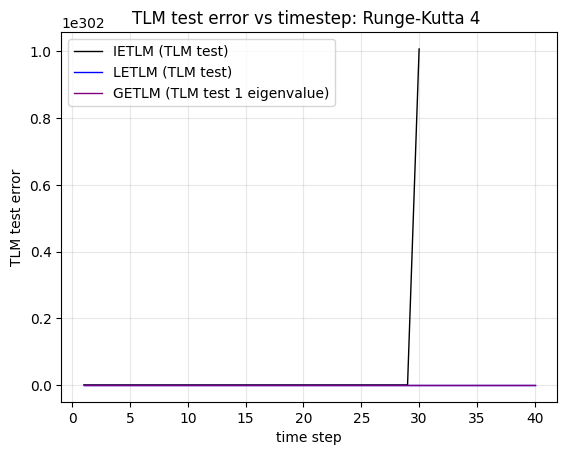

<Figure size 640x480 with 0 Axes>

In [10]:
plt.plot(x_values, IETLM_TT_result, label='IETLM (TLM test)', color='black', linewidth=1)
plt.plot(x_values, LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values, GETLM_1_TT_result, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
# plt.plot(x_values, GETLM_2_TT_result, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
# plt.plot(x_values, GETLM_3_TT_result, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
# plt.plot(x_values, GETLM_4_TT_result, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Runge-Kutta 4 ")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

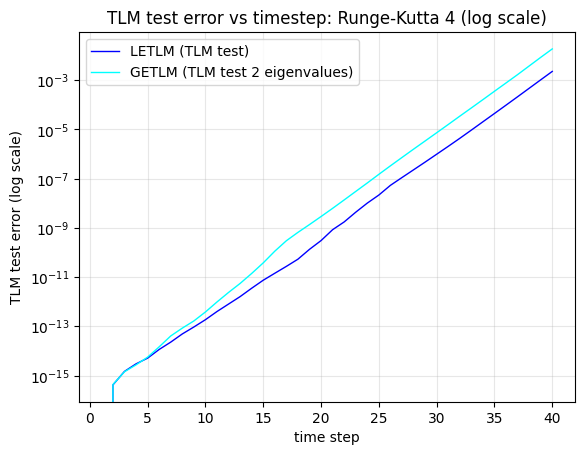

<Figure size 640x480 with 0 Axes>

In [11]:
# plt.plot(x_values, IETLM_TT_result, label='IETLM (TLM test)', color='black', linewidth=1)
plt.plot(x_values, LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
# plt.plot(x_values, GETLM_1_TT_result, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)

plt.plot(x_values, GETLM_2_TT_result, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
# plt.plot(x_values, GETLM_3_TT_result, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
# plt.plot(x_values, GETLM_4_TT_result, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Runge-Kutta 4 (log scale)")
plt.xlabel("time step")
plt.ylabel("TLM test error (log scale)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()


In [12]:
%store LETLM_TT_result
%store GETLM_2_TT_result

Stored 'LETLM_TT_result' (Tensor)
Stored 'GETLM_2_TT_result' (Tensor)
